# Etapa 2: Generación del Diccionario de Ondículas de Morlet

Este notebook implementa el **Paso 2** del flujo de trabajo: la síntesis de un diccionario redundante tridimensional de ondículas de Morlet en el espacio $[Frecuencia \times Fase \times Tiempo]$.

### Formulación Matemática
Cada ondícula compleja de Morlet $m(t; f, \phi)$ se evalúa como:

$$m(t; f, \phi) = \exp\left( -t^2 \cdot f^2 \cdot \ln(2/k) \right) \cdot \exp(i 2\pi f t) \cdot \exp(i \phi)$$

donde:
* $f$: Frecuencia central (Hz).
* $\phi$: Ángulo de fase (grados o radianes).
* $t$: Coordenada temporal relativa a la envolvente (s).
* $k$: Parámetro de ciclos de la ondícula (típicamente $k = 0.2$).

In [1]:
import os
import sys
import numpy as np
import matplotlib.pyplot as plt

MODULE_DIR = os.path.abspath('../3_Python_Code')
if MODULE_DIR not in sys.path:
    sys.path.insert(0, MODULE_DIR)

from config import MorletDictionaryConfig
from morlet_dictionary import compute_morlet_atom, build_morlet_dictionary

print('Módulo de diccionario cargado.')

Módulo de diccionario cargado.


## 1. Configuración de Parámetros del Diccionario

Definimos el rango de frecuencias exploradas (de $5$ a $120\text{ Hz}$), el paso angular de fase ($-180^\circ$ a $+180^\circ$) y la ventana temporal.

In [2]:
dict_cfg = MorletDictionaryConfig(
    f_min=5.0,
    f_max=100.0,
    df=2.0,
    phase_min_deg=-180.0,
    phase_max_deg=180.0,
    dphase_deg=10.0,
    wavelet_half_duration_s=0.25,
    k_param=0.2
)
sample_rate_s = 0.002

morlet_dict, f_vec, phi_vec, t_atom = build_morlet_dictionary(dict_cfg, sample_rate_s)
print(f'Dimensiones del diccionario tridimensional: {morlet_dict.shape}')
print(f'Frecuencias evaluadas: {len(f_vec)} valores ({f_vec[0]} a {f_vec[-1]} Hz).')
print(f'Fases evaluadas: {len(phi_vec)} valores ({phi_vec[0]}° a {phi_vec[-1]}°).')
print(f'Muestras temporales: {len(t_atom)} muestras ({t_atom[0]*1000:.0f} a {t_atom[-1]*1000:.0f} ms).')

Dimensiones del diccionario tridimensional: (48, 37, 251)
Frecuencias evaluadas: 48 valores (5.0 a 99.0 Hz).
Fases evaluadas: 37 valores (-180.0° a 180.0°).
Muestras temporales: 251 muestras (-250 a 250 ms).


## 2. Inspección Visual de Cortes del Diccionario

Visualizamos la dependencia con la frecuencia, el comportamiento ante rotaciones de fase y la huella energética espectral en el plano tiempo-frecuencia.

<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\c'
<>:20: SyntaxWarning: invalid escape sequence '\p'
<>:20: SyntaxWarning: invalid escape sequence '\c'
/var/folders/mr/h29136197b778zqwcvr204200000gn/T/ipykernel_88681/913474527.py:20: SyntaxWarning: invalid escape sequence '\p'
  axes[1].plot(t_atom * 1000, np.real(atom), label=f'$\phi = {ph}^\circ$', color=c, linewidth=1.4)
/var/folders/mr/h29136197b778zqwcvr204200000gn/T/ipykernel_88681/913474527.py:20: SyntaxWarning: invalid escape sequence '\c'
  axes[1].plot(t_atom * 1000, np.real(atom), label=f'$\phi = {ph}^\circ$', color=c, linewidth=1.4)


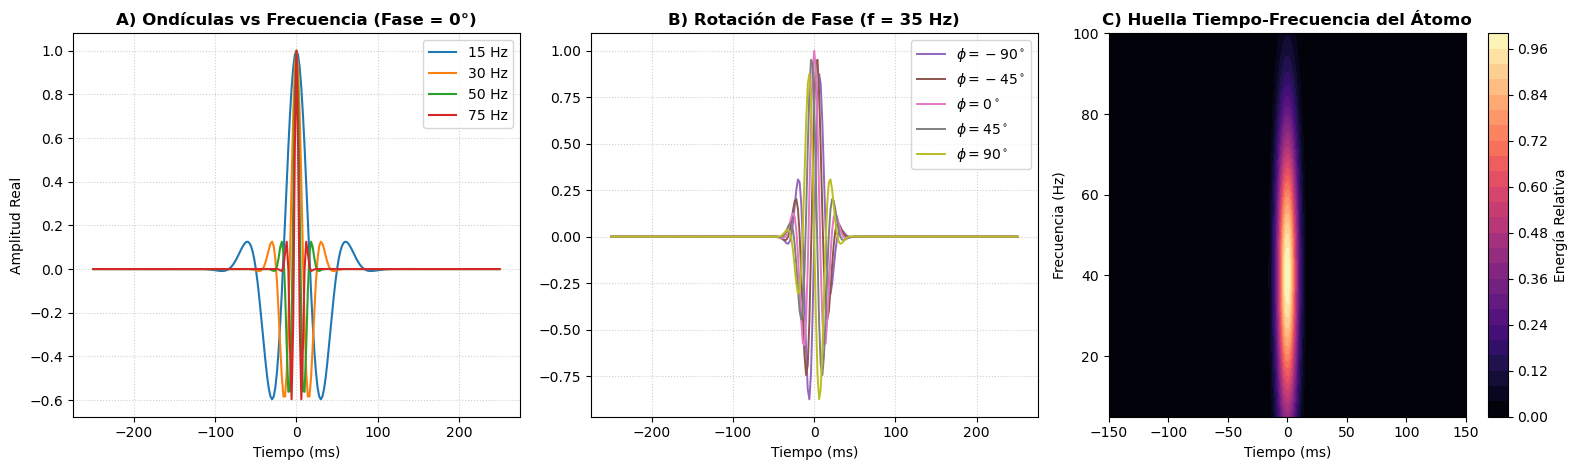

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# Corte A: Frecuencias crecientes a fase 0°
freqs_show = [15, 30, 50, 75]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
for f, c in zip(freqs_show, colors):
    atom = compute_morlet_atom(t_atom, frequency_hz=f, phase_deg=0.0, k_param=dict_cfg.k_param)
    axes[0].plot(t_atom * 1000, np.real(atom), label=f'{f} Hz', color=c, linewidth=1.5)
axes[0].set_title('A) Ondículas vs Frecuencia (Fase = 0°)', fontweight='bold')
axes[0].set_xlabel('Tiempo (ms)')
axes[0].set_ylabel('Amplitud Real')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Corte B: Rotación de fase a 35 Hz
phases_show = [-90, -45, 0, 45, 90]
phase_colors = ['#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22']
for ph, c in zip(phases_show, phase_colors):
    atom = compute_morlet_atom(t_atom, frequency_hz=35.0, phase_deg=ph, k_param=dict_cfg.k_param)
    axes[1].plot(t_atom * 1000, np.real(atom), label=f'$\phi = {ph}^\circ$', color=c, linewidth=1.4)
axes[1].set_title('B) Rotación de Fase (f = 35 Hz)', fontweight='bold')
axes[1].set_xlabel('Tiempo (ms)')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Corte C: Huella espectral del átomo de Morlet en (t, f)
f_axis = np.linspace(5, 100, 200)
t_axis = np.linspace(-150, 150, 200)
T, F = np.meshgrid(t_axis / 1000, f_axis)
f0 = 40.0
sigma_t = np.sqrt(np.log(2.0 / dict_cfg.k_param)) / (2.0 * np.pi * f0)
sigma_f = 1.0 / (2.0 * np.pi * sigma_t)
envelope_2d = np.exp(-0.5 * (T / sigma_t)**2 - 0.5 * ((F - f0) / sigma_f)**2)
im = axes[2].contourf(t_axis, f_axis, envelope_2d, levels=25, cmap='magma')
axes[2].set_title('C) Huella Tiempo-Frecuencia del Átomo', fontweight='bold')
axes[2].set_xlabel('Tiempo (ms)')
axes[2].set_ylabel('Frecuencia (Hz)')
plt.colorbar(im, ax=axes[2], label='Energía Relativa')

plt.tight_layout()
plt.show()